In [47]:
import numpy as np
import matplotlib.pyplot as plt

# 設定
filename = "data_05252613.csv"
n = 1                 # セグメント長 = 全データ長の約1/n
smooth_points = 1     # 移動平均の点数（1なら平滑化なし）

In [48]:
# データ読み込み
csv = np.genfromtxt(filename, delimiter=",", names=True)
t = np.asarray(csv["t"], dtype=float)
x = np.asarray(csv["x"], dtype=float)

dt = np.mean(np.diff(t))

# 線形トレンド除去: 最小二乗フィットにより線形トレンドを検出し、時系列から引く
trend = np.polyval(np.polyfit(t, x, 1), t)
x_detrended = x - trend

# プレホワイトニング: AR(1)モデルによりレッドノイズを除去。
# (τ=1のCorrelation function)=(τ=1のCovariance function)/(τ=0のCovariance function)からrを推定。
# Red Noise成分を除去
r = np.dot(x_detrended[1:], x_detrended[:-1]) / np.dot(x_detrended[:-1], x_detrended[:-1])
y = x_detrended[1:] - r * x_detrended[:-1]
y -= y.mean()

print(f"サンプル数: {len(x)}, dt: {dt:g}, AR(1)係数 r: {r:.4f}")


サンプル数: 4096, dt: 1, AR(1)係数 r: 0.5898


In [ ]:
# セグメント分割（50%オーバーラップ）
segment_length = len(y) // n
step = segment_length // 2

# segment長が一番近い2^nになるようにZero Padding
nfft = 2 ** int(np.ceil(np.log2(segment_length)))
# サンプリング周波数をつくる
fs = 1 / dt
# Fourier変換に使う周波数配列(>0)をつくる
frequency = np.fft.rfftfreq(nfft, d=dt)

# Hanningテーパー(対称: 分母N-1)
window = np.hanning(segment_length)

# segmentごとにZero Padding → FFT → PSD → 6. 移動平均
kernel = np.ones(smooth_points)
segment_psds = []
for start in range(0, len(y) - segment_length + 1, step):
    segment = y[start:start + segment_length]  
    #segment = segment * window               #Hanningテーパー有りの場合はコメントアウトを外す
    fft = np.fft.rfft(segment, n=nfft)        # FFTを計算。segment長がnfftより短い場合はゼロパディング
    psd = np.abs(fft)**2 / (fs * segment_length)  #Power Spectral Densityを計算し、segment長で規格化(全エネルギーを保つ)。
    psd[1:-1] *= 2                           # 片側PSDにまとめる（nfftは偶数）

    # 移動平均を計算。※端(移動平均の点数に満たない部分)では、データのある部分の数だけで移動平均を計算。
    psd_smooth = np.convolve(psd, kernel, mode="same") / np.convolve(
        np.ones_like(psd), kernel, mode="same"
    )
    segment_psds.append(psd_smooth)

# セグメントごとのスペクトルを平均
mean_psd = np.mean(segment_psds, axis=0)
print(f"セグメント長: {segment_length}, セグメント数: {len(segment_psds)}, FFT長: {nfft}")


セグメント長: 4095, セグメント数: 1, FFT長: 4096


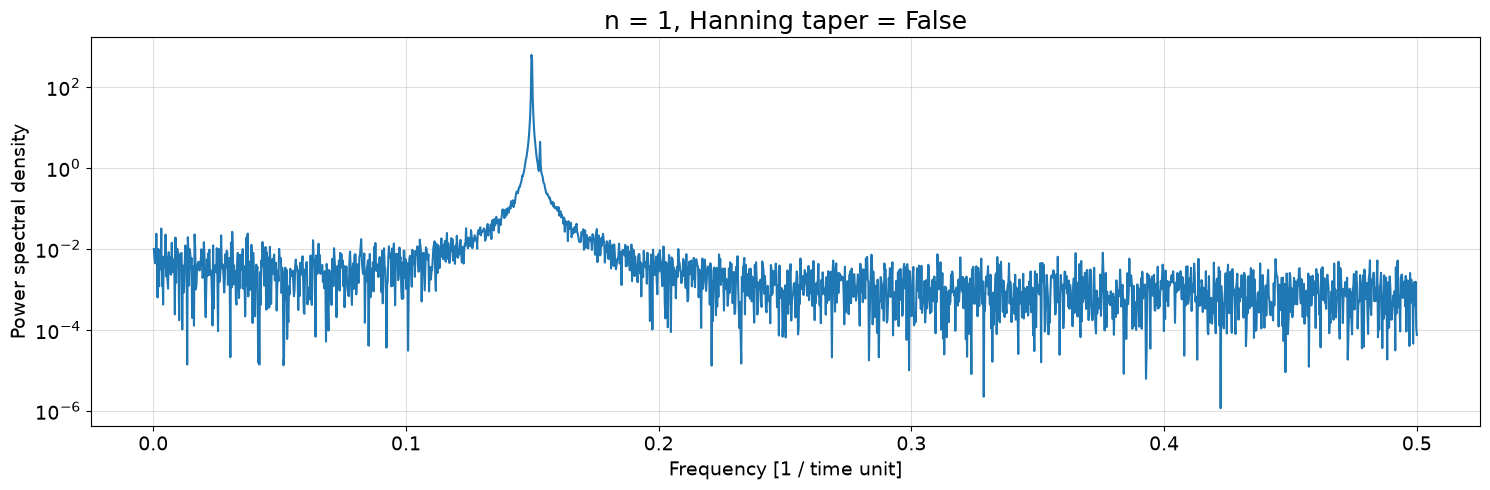

In [52]:
# パワースペクトルを描画
plt.figure(figsize=(15, 5))
plt.semilogy(frequency[1:], mean_psd[1:])  # 周波数0は対数軸に表示できない
taper = False  # True: Hanningテーパーあり、False: なし
plt.title(f"n = {n}, Hanning taper = {taper}",
          fontsize=18)
plt.xlabel("Frequency [1 / time unit]", fontsize = 14)
plt.ylabel("Power spectral density", fontsize = 14)
plt.grid(True, which="both", alpha=0.4)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.tight_layout()
plt.show()